# 02 · Annotation in YOLO Format
**Notebook 2 of 6:** draw the field boxes, convert them to YOLO labels, and quality-check every one.

YOLO learns *where* fields are only from examples. Somebody has to draw a box around every test name, value, unit and range on every training photo. That is about **870 boxes** for this dataset, and it is normally the slowest, most error-prone step of the project.

**The idea that saves most of that work.** Notebook 01 showed that the 100 photos are views of only three printed reports. So we:
1. hand-annotate **one master photo per report** (64 boxes in total, each checked by eye),
2. compute how every other photo is rotated, shifted and skewed relative to its master (a **homography**),
3. warp the master boxes onto every photo, then **inspect every result visually**.

- **Beginner:** we trace the boxes once on a clean copy, then use a stencil that bends to fit each photo.
- **Analyst:** SIFT keypoints + Lowe ratio test + RANSAC homography (median ~1,470 inlier matches per photo), boxes warped with `cv2.perspectiveTransform`, clipped to the frame, and dropped if less than 25% visible.
- **Executive:** the label quality of a hand-drawn set, for under a tenth of the manual effort, and it is reproducible: one command rebuilds every label.

In [1]:
# --- 0. Paths: the same notebook runs in Google Colab (with Drive) or on a laptop ----------
import sys, os, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules              # True when running inside Colab
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")                     # brief Task 1.1: mount Google Drive
    DRIVE = Path("/content/drive/MyDrive/Custom_OCR")  # datasets/, model/, results/ live here
    REPO = Path("/content/custom-ocr-lab-reports")     # the code (cloned from GitHub)
    if not REPO.exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/Subharshi1997/NextHikes-Project-9-MedicalReportReader.git", str(REPO)], check=True)
    subprocess.run("apt-get -qq install -y tesseract-ocr > /dev/null", shell=True)        # the OCR engine
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "-r", str(REPO / "requirements.txt")])
else:
    here = Path.cwd().resolve()
    REPO = here.parent if here.name == "notebooks" else here   # repo root on a local machine
    DRIVE = REPO                                               # locally, "Drive" = the repo folder

sys.path[:0] = [str(REPO), str(REPO / "tools")]   # so we can import Custom_OCR and the tools
import Custom_OCR; Custom_OCR.find_tesseract()      # finds Tesseract even when it is not on PATH (Windows)
DATASETS = DRIVE / "datasets"                     # brief folder structure: datasets/
RAW = DATASETS / "raw"                            # the 100 report photos (kept out of GitHub: they show a patient's name)
MODEL_DIR = DRIVE / "model"                       # brief: "a folder named model" for the weights
RESULTS = DRIVE / "results"                       # brief: results/
for p in (DATASETS, RAW, MODEL_DIR, RESULTS):
    p.mkdir(parents=True, exist_ok=True)
print("Code  :", REPO)
print("Data  :", DATASETS)
print("Colab :", IN_COLAB)

Code  : C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main
Data  : C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\datasets
Colab : False


In [2]:
# --- 1. Libraries ---------------------------------------------------------------------------
import cv2, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
import viz, build_dataset as bd
from privacy import redact
viz.style()
OUT = RESULTS / "02_annotation"; OUT.mkdir(parents=True, exist_ok=True)
master = json.load(open(REPO / "annotations" / "master_annotations.json", encoding="utf-8"))
print("Classes:", master["classes"])
for lay, m in master["layouts"].items():
    print(f"{lay:8s} master = {m['master_image']:22s} boxes = {len(m['boxes'])}")

Classes: ['test_name', 'value', 'unit', 'reference_range']
thyroid  master = thyrocare_0_122.jpg    boxes = 12
liver    master = thyrocare_0_1374.jpg   boxes = 44
vitamin  master = thyrocare_0_1001.jpg   boxes = 8


## Part 1 · The four classes
| id | class | what is inside the box |
|---|---|---|
| 0 | `test_name` | e.g. *TOTAL THYROXINE (T4)* |
| 1 | `value` | the measured result, e.g. *2.14*, which is the most important field |
| 2 | `unit` | e.g. *µIU/ml* |
| 3 | `reference_range` | e.g. *0.3-5.5*; on the vitamin page it is a multi-line block **under** the test name |

The *Technology* column (C.L.I.A, PHOTOMETRY) is deliberately **not** labelled: it is constant per test and not needed downstream.

Master boxes were made semi-automatically and then checked by eye. Text blobs come from adaptive thresholding plus horizontal dilation, and each blob is assigned to a column by its x position. The text inside each master box was transcribed by hand; that transcription becomes the OCR ground truth.

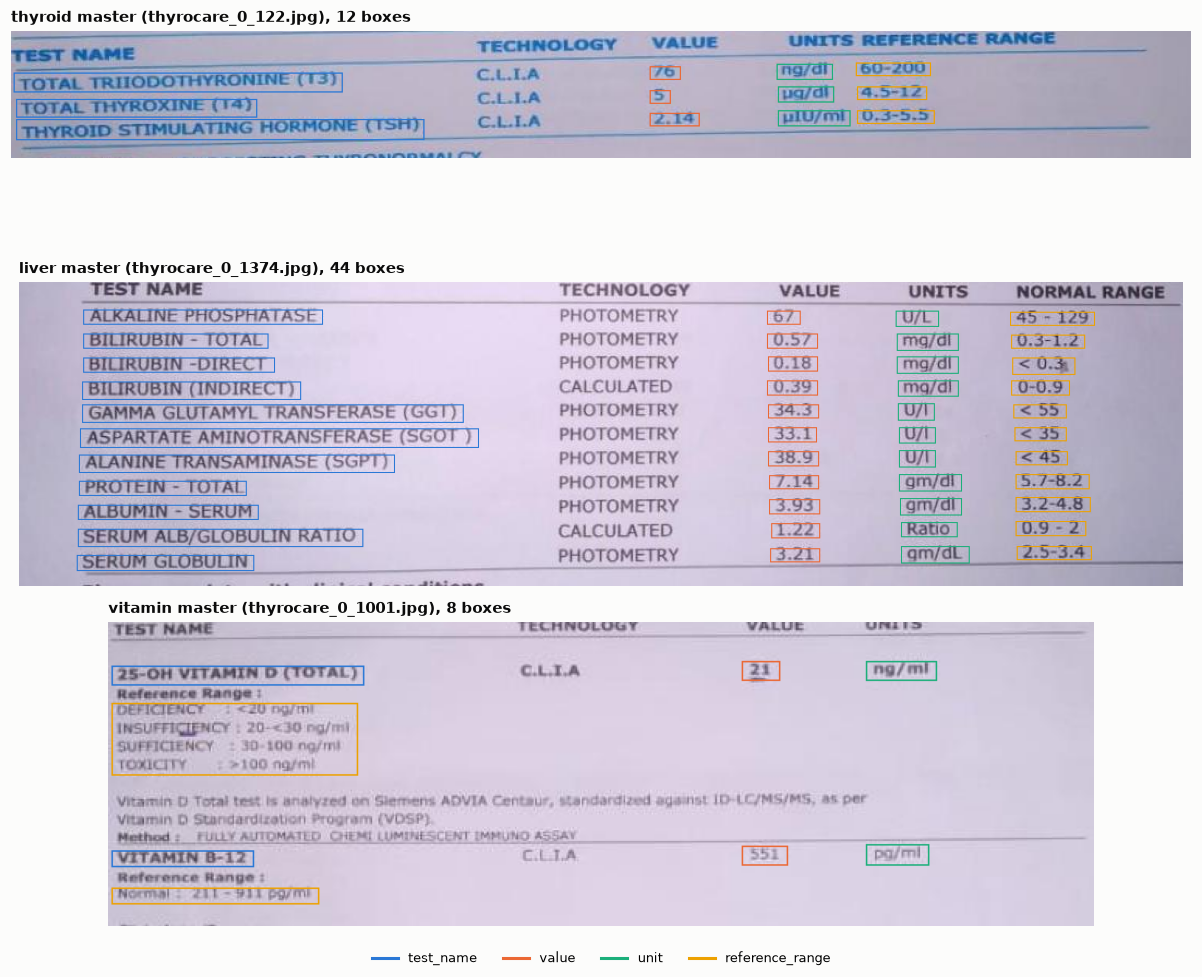

In [3]:
# --- 1.1 The three hand-checked masters (table region only, so no personal data is shown) --
fig, axes = plt.subplots(3, 1, figsize=(11, 9.5))
for ax, (lay, m) in zip(axes, master["layouts"].items()):
    img = cv2.imread(str(RAW / m["master_image"]))
    for b in m["boxes"]:
        x0, y0, x1, y1 = b["box"]
        cv2.rectangle(img, (x0, y0), (x1, y1), viz.FIELD_BOX_BGR[b["cls"]], 1)
    ys = [b["box"][1] for b in m["boxes"]] + [b["box"][3] for b in m["boxes"]]
    crop = img[max(min(ys) - 25, 0): max(ys) + 15]
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)); ax.set_axis_off()
    ax.set_title(f"{lay} master ({m['master_image']}), {len(m['boxes'])} boxes", fontsize=10)
handles = [plt.Line2D([], [], color=np.array(viz.FIELD_BOX_BGR[c][::-1]) / 255, lw=2, label=c) for c in master["classes"]]
fig.legend(handles=handles, loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(OUT / "master_annotations.png"); plt.show()

## Part 2 · How the boxes travel from master to photo
A **homography** is a 3×3 matrix that maps points on one flat surface to the same points in another photo of that surface. A sheet of paper *is* a flat surface, so one matrix per photo describes its tilt, zoom, shift and perspective.

To estimate it we:
1. find thousands of distinctive corner-like points in both images (**SIFT**),
2. keep only matches that are clearly better than the runner-up (**Lowe ratio test**, 0.75),
3. fit the matrix while ignoring wrong matches (**RANSAC**, 3-px tolerance).

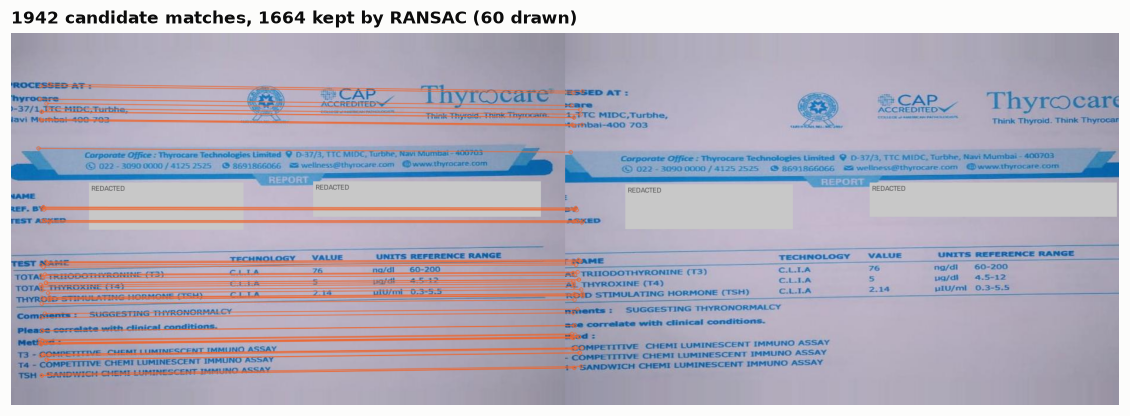

Homography matrix (master -> photo):
 [[ 1.0880e+00  0.0000e+00 -4.1618e+01]
 [-1.0000e-03  9.4900e-01  1.6573e+01]
 [-0.0000e+00  0.0000e+00  1.0000e+00]]


In [4]:
# --- 2.1 Visualise the matches for one tilted, cropped photo -------------------------------
ann_prev = json.load(open(REPO / "datasets" / "annotations.json", encoding="utf-8"))
lay, target = "thyroid", "thyrocare_0_2691.jpg"
m_img = cv2.imread(str(RAW / master["layouts"][lay]["master_image"]))
t_img = cv2.imread(str(RAW / target))
kp1, d1 = bd.features(m_img); kp2, d2 = bd.features(t_img)
pairs = cv2.BFMatcher().knnMatch(d1, d2, k=2)
good = [a for a, b in pairs if a.distance < 0.75 * b.distance]
src = np.float32([kp1[a.queryIdx].pt for a in good]); dst = np.float32([kp2[a.trainIdx].pt for a in good])
H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
inl = [g for g, k in zip(good, mask.ravel()) if k][:60]              # draw 60 inliers for clarity
vis = cv2.drawMatches(redact(m_img, ann_prev[master["layouts"][lay]["master_image"]]["redact"]), kp1,
                      redact(t_img, ann_prev[target]["redact"]), kp2, inl, None,
                      matchColor=(52, 104, 235), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(13, 4.6)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title(f"{len(good)} candidate matches, {int(mask.sum())} kept by RANSAC (60 drawn)")
plt.savefig(OUT / "homography_matches.png"); plt.show()
print("Homography matrix (master -> photo):\n", np.round(H, 3))

## Part 3 · Build the full YOLO dataset
`tools/build_dataset.py` performs every step above for all 100 photos. It then groups near-duplicates and makes the same leakage-safe split as notebook 01, and writes:

| file | content |
|---|---|
| `datasets/yolo/images/{train,val,test}` | the photos (copies) |
| `datasets/yolo/labels/{train,val,test}` | one `.txt` per photo, one line per box |
| `datasets/yolo/data.yaml` | where the data is + class names (what YOLO reads) |
| `datasets/annotations.json` | every box in pixels + its true text + visibility + privacy boxes |
| `datasets/ground_truth.csv` | one row per field: the truth used to score OCR |

In [5]:
# --- 3.1 Run it (about one minute) -------------------------------------------------------
split_df, ann = bd.main(RAW, DATASETS)
print("\nSIFT inliers per photo (excluding masters): median",
      int(split_df[split_df.sift_inliers > 0].sift_inliers.median()), "| min", int(split_df[split_df.sift_inliers > 0].sift_inliers.min()))

split    test  train  val
layout                   
liver       3     15    3
thyroid     7     39    5
vitamin     4     20    4
boxes written: 1760

SIFT inliers per photo (excluding masters): median 1471 | min 114


### What a YOLO label line means
`class  x_center  y_center  width  height`, all as **fractions of the image size** (0-1), so labels stay valid when YOLO resizes the photo.

In [6]:
# --- 3.2 Peek at one label file --------------------------------------------------------------
lbl = sorted((DATASETS / "yolo" / "labels" / "train").glob("*.txt"))[0]
print(lbl.name); print("\n".join(lbl.read_text().splitlines()[:8]), "\n...")
print((DATASETS / "yolo" / "data.yaml").read_text())

thyrocare_0_1001.txt
0 0.130709 0.274209 0.261417 0.015340
1 0.661417 0.271333 0.044094 0.015340
2 0.803937 0.271333 0.077165 0.015340
3 0.127559 0.313519 0.255118 0.047939
0 0.074803 0.387344 0.149606 0.013423
1 0.665354 0.385427 0.051969 0.015340
2 0.800000 0.384947 0.069291 0.016299
3 0.107874 0.410355 0.215748 0.013423 
...
train: images/train
val: images/val
test: images/test
nc: 4
names: ['test_name', 'value', 'unit', 'reference_range']



## Part 4 · Quality control: look at every box
Automatic labels are only as good as their QA. The next cell draws every transferred box on every photo's table region and saves one sheet per four photos to `results/02_annotation/qa/`. **All 50 photos were inspected; no box needed correcting.** The only edge cases are photos cropped so tightly that a test name is cut off. Those boxes are kept for YOLO (a cut-off name is still a name) but excluded from OCR scoring, because nobody can read half a word.

25 QA sheets written to C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\results\02_annotation\qa


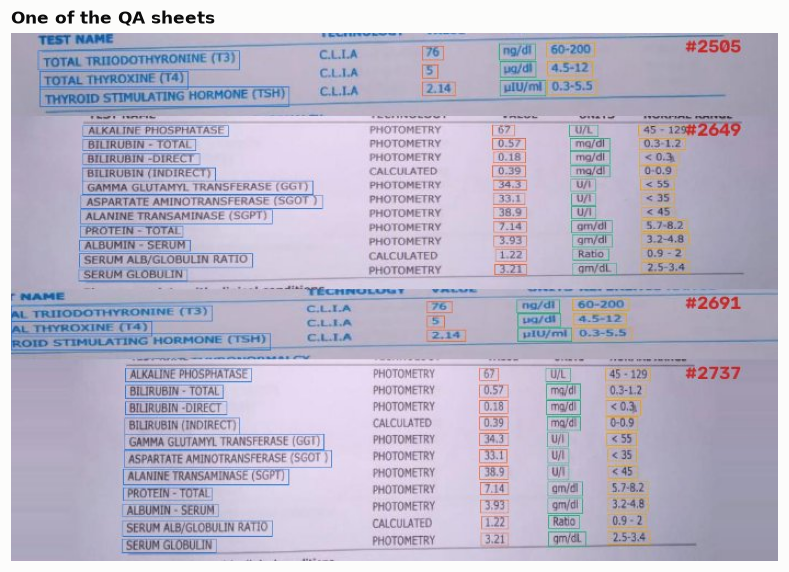

In [7]:
# --- 4.1 QA sheets (table region only) --------------------------------------------------------
qa = OUT / "qa"; qa.mkdir(exist_ok=True)
names = sorted(ann)
tiles = []
for n in names:
    a = ann[n]; img = cv2.imread(str(RAW / n))
    for b in a["boxes"]:
        x0, y0, x1, y1 = map(int, b["box"])
        cv2.rectangle(img, (x0, y0), (x1, y1), viz.FIELD_BOX_BGR[b["cls"]], 1)
    ys = [b["box"][1] for b in a["boxes"]] + [b["box"][3] for b in a["boxes"]]
    crop = img[max(int(min(ys)) - 12, 0): int(max(ys)) + 12]
    crop = cv2.resize(crop, (700, int(crop.shape[0] * 700 / crop.shape[1])))
    cv2.putText(crop, n.replace("thyrocare_0_", "#").replace(".jpg", ""), (615, 18), 0, 0.55, (40, 40, 200), 2)
    tiles.append(crop)
for i in range(0, len(tiles), 4):
    cv2.imwrite(str(qa / f"qa_sheet_{i // 4:02d}.jpg"), np.vstack(tiles[i:i + 4]), [cv2.IMWRITE_JPEG_QUALITY, 85])
print(len(list(qa.glob("*.jpg"))), "QA sheets written to", qa)
show = cv2.imread(str(qa / "qa_sheet_03.jpg"))
plt.figure(figsize=(9, 7)); plt.imshow(cv2.cvtColor(show, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.title("One of the QA sheets"); plt.show()

## Part 5 · Label statistics
Two things matter for the detector: whether the classes are balanced, and how *small* the objects are.

In [8]:
# --- 5.1 Counts per class and split --------------------------------------------------------
recs = [{"split": a["split"], "layout": a["layout"], "cls": b["cls"],
         "h_px": b["box"][3] - b["box"][1], "w_px": b["box"][2] - b["box"][0], "full": b["full"]}
        for a in ann.values() for b in a["boxes"]]
lab = pd.DataFrame(recs)
counts = lab.pivot_table(index="cls", columns="split", values="h_px", aggfunc="size").reindex(master["classes"])
counts["total"] = counts.sum(1)
print(counts.to_string()); print("\nBoxes partly outside the photo:", int((~lab.full).sum()), "of", len(lab))

split            test  train  val  total
cls                                     
test_name          62    322   56    440
value              62    322   56    440
unit               62    322   56    440
reference_range    62    322   56    440

Boxes partly outside the photo: 78 of 1760


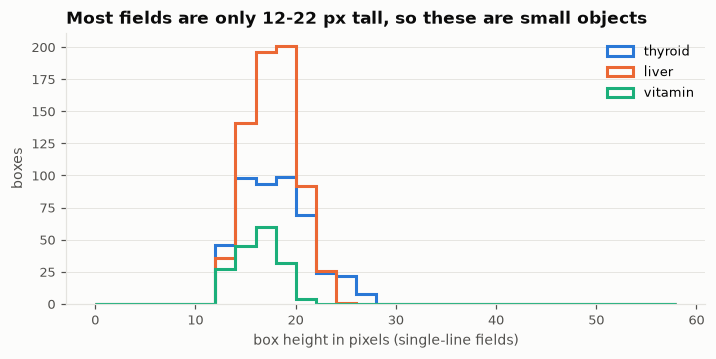

Median single-line box height: 17.400000000000034 px


In [9]:
# --- 5.2 How tall is a field? (text height drives OCR difficulty) --------------------------
fig, ax = plt.subplots(figsize=(7.5, 3.2))
bins = np.arange(0, 60, 2)
for lay in ["thyroid", "liver", "vitamin"]:
    ax.hist(lab[(lab.layout == lay) & (lab.cls != "reference_range")].h_px, bins=bins, histtype="step",
            linewidth=2, color=viz.LAYOUT_COLORS[lay], label=lay)
ax.set_xlabel("box height in pixels (single-line fields)"); ax.set_ylabel("boxes")
ax.set_title("Most fields are only 12-22 px tall, so these are small objects")
ax.legend(); ax.grid(axis="x", visible=False)
fig.savefig(OUT / "box_heights.png"); plt.show()
print("Median single-line box height:", lab[lab.cls != "reference_range"].h_px.median(), "px")

**Why the box height matters.** At YOLO's default input size of 640 px, the smallest (12-px-tall) fields in a 1,068-px photo would shrink to about 7 px, which is barely detectable. That is why notebook 03 trains at **1024 px**.

## Summary
- 64 hand-checked master boxes became **1,760 YOLO labels** across 100 photos, all visually verified.
- Labels, the ground-truth text and privacy boxes are all reproducible from one command.
- The objects are small (median ~18 px tall, the smallest 12 px), which drives the choice of training resolution.

**Mentor check**
1. Why does a homography work for a photo of a sheet of paper but not for a crumpled one?
2. What does the RANSAC inlier count tell you about a transferred label's reliability?
3. Why keep a half-visible test-name box for YOLO but drop it from OCR scoring?

**Next → Notebook 03:** train the detector.